In [ ]:
import pandas as pd

df = pd.read_csv("/content/student_study_habits_synthetic.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (120, 5)


,student_id,study_hours_per_day,attendance_percent,sleep_hours_per_night,exam_score_percent
0,1,4.26,67.8,6.12,85.0
1,2,2.24,79.8,6.91,83.9
2,3,4.93,80.2,5.24,96.6
3,4,5.21,91.6,5.53,85.9
4,5,0.87,86.4,9.13,79.8


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
print(df.info())

Column names:
['student_id', 'study_hours_per_day', 'attendance_percent', 'sleep_hours_per_night', 'exam_score_percent']

Missing values:
student_id               0
study_hours_per_day      0
attendance_percent       0
sleep_hours_per_night    0
exam_score_percent       0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             120 non-null    int64  
 1   study_hours_per_day    120 non-null    float64
 2   attendance_percent     120 non-null    float64
 3   sleep_hours_per_night  120 non-null    float64
 4   exam_score_percent     120 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 4.8 KB
None


In [ ]:
features = [
    "study_hours_per_day",
    "attendance_percent",
    "sleep_hours_per_night",
    "exam_score_percent"
]

X = df[features].copy()

print("Selected Features:")
print(X.head())

print("\nShape:", X.shape)

Selected Features:
   study_hours_per_day  attendance_percent  sleep_hours_per_night  \
0                 4.26                67.8                   6.12   
1                 2.24                79.8                   6.91   
2                 4.93                80.2                   5.24   
3                 5.21                91.6                   5.53   
4                 0.87                86.4                   9.13   

   exam_score_percent  
0                85.0  
1                83.9  
2                96.6  
3                85.9  
4                79.8  

Shape: (120, 4)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled data shape:", X_scaled.shape)

Standardization completed!
Scaled data shape: (120, 4)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("PCA completed!")
print("PCA shape:", X_pca.shape)

PCA completed!
PCA shape: (120, 4)


In [ ]:
import matplotlib.pyplot as plt

explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f} ({variance*100:.2f}%)")

print("\nCumulative Explained Variance:")
print(explained_variance.cumsum())

Explained Variance Ratio:
PC1: 0.3615 (36.15%)
PC2: 0.2619 (26.19%)
PC3: 0.2570 (25.70%)
PC4: 0.1196 (11.96%)

Cumulative Explained Variance:
[0.36153054 0.62340406 0.88038612 1.        ]


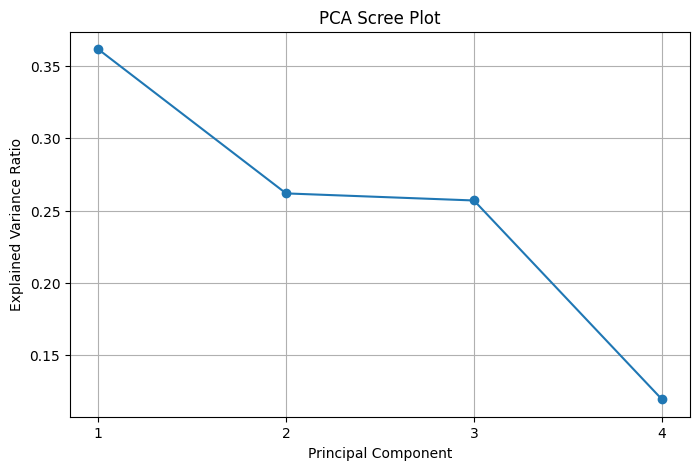

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.xticks(range(1, 5))
plt.grid(True)

plt.show()

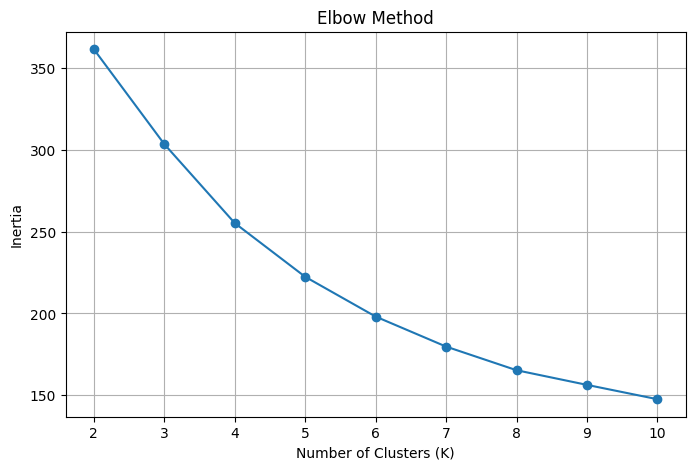

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

print("Silhouette Scores:")
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: {score:.4f}")

Silhouette Scores:
K = 2: 0.2224
K = 3: 0.1969
K = 4: 0.2042
K = 5: 0.2119
K = 6: 0.2075
K = 7: 0.2088
K = 8: 0.2203
K = 9: 0.2135
K = 10: 0.1992


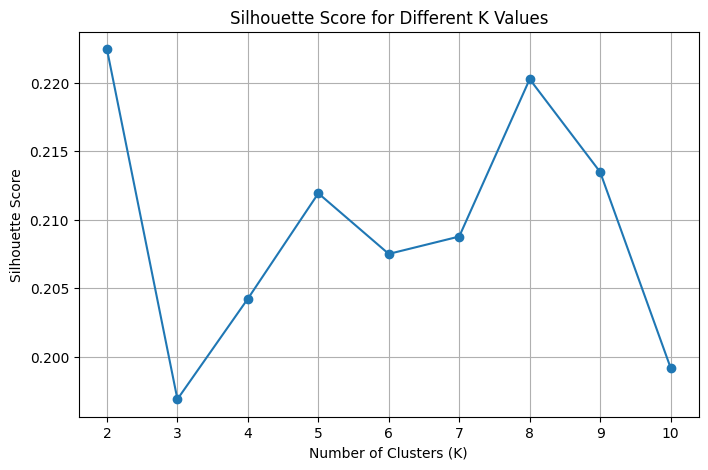

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [ ]:
# Final K-Means Clustering

optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("K-Means clustering completed!")
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

display(df.head())

K-Means clustering completed!

Cluster counts:
Cluster
0    41
1    44
2    35
Name: count, dtype: int64


,student_id,study_hours_per_day,attendance_percent,sleep_hours_per_night,exam_score_percent,Cluster
0,1,4.26,67.8,6.12,85.0,1
1,2,2.24,79.8,6.91,83.9,2
2,3,4.93,80.2,5.24,96.6,0
3,4,5.21,91.6,5.53,85.9,0
4,5,0.87,86.4,9.13,79.8,2


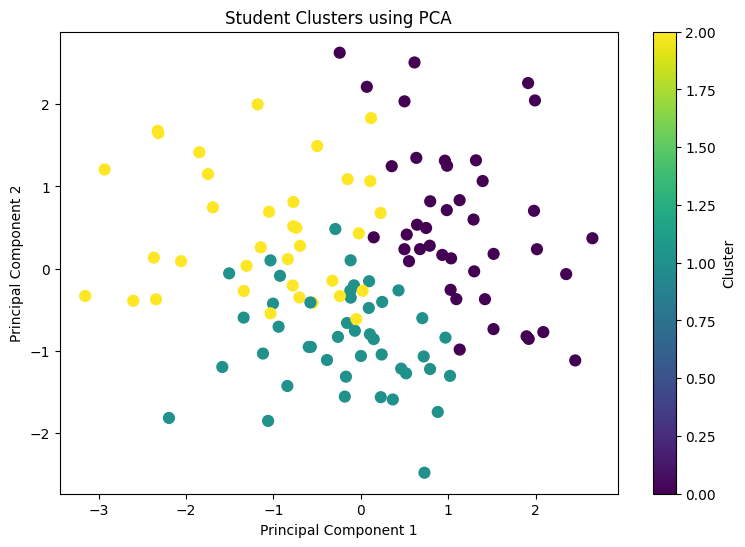

In [ ]:
# 2D PCA Visualization

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=clusters,
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Clusters using PCA")
plt.colorbar(scatter, label="Cluster")

plt.show()

In [ ]:
import plotly.express as px

# 3 principal components
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

# Create 3D DataFrame
pca_df = pd.DataFrame(
    X_pca_3d,
    columns=["PC1", "PC2", "PC3"]
)

pca_df["Cluster"] = clusters.astype(str)

# 3D visualization
fig = px.scatter_3d(
    pca_df,
    x="PC1",
    y="PC2",
    z="PC3",
    color="Cluster",
    title="3D PCA Visualization of Student Clusters",
    labels={
        "PC1": "Principal Component 1",
        "PC2": "Principal Component 2",
        "PC3": "Principal Component 3"
    }
)

fig.update_traces(marker=dict(size=6))
fig.show()

In [ ]:
# Cluster-wise analysis

cluster_summary = df.groupby("Cluster")[[
    "study_hours_per_day",
    "attendance_percent",
    "sleep_hours_per_night",
    "exam_score_percent"
]].mean().round(2)

display(cluster_summary)

,study_hours_per_day,attendance_percent,sleep_hours_per_night,exam_score_percent
Cluster,,,,
0,4.55,81.34,6.95,94.40
1,3.72,68.90,7.38,84.95
2,2.71,84.10,6.81,80.85


In [ ]:
print("CONCLUSION")
print("-" * 50)

print("1. The dataset was standardized before applying PCA.")
print("2. PCA was used to reduce the dimensionality of the dataset.")
print("3. K-Means clustering was applied to group students based on study habits.")
print("4. The Elbow Method and Silhouette Score were used to evaluate the number of clusters.")
print("5. PCA visualizations helped to understand the separation of student clusters.")
print("6. The clusters represent students with different study, attendance, sleep, and exam-score patterns.")

CONCLUSION
--------------------------------------------------
1. The dataset was standardized before applying PCA.
2. PCA was used to reduce the dimensionality of the dataset.
3. K-Means clustering was applied to group students based on study habits.
4. The Elbow Method and Silhouette Score were used to evaluate the number of clusters.
5. PCA visualizations helped to understand the separation of student clusters.
6. The clusters represent students with different study, attendance, sleep, and exam-score patterns.
